<a href="https://colab.research.google.com/github/valdelacruz991-lang/LABORATORY_EXAM/blob/main/DELACRUZ_LABORATORY_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Preprocessing & Pipeline Construction
We will start by importing the necessary libraries, loading the `telecom_churn.csv` dataset, addressing missing values, and encoding categorical variables.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Try to load telecom_churn.csv; if it is missing, generate a simulated dataset
try:
    df = pd.read_csv('telecom_churn.csv')
    print("Dataset loaded successfully from telecom_churn.csv!")
except FileNotFoundError:
    print("telecom_churn.csv not found. Generating simulated telecom customer churn dataset...")
    np.random.seed(42)
    n_samples = 1000
    df = pd.DataFrame({
        'gender': np.random.choice(['Male', 'Female'], size=n_samples),
        'SeniorCitizen': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]),
        'Partner': np.random.choice(['Yes', 'No'], size=n_samples),
        'Dependents': np.random.choice(['Yes', 'No'], size=n_samples),
        'tenure': np.random.randint(1, 72, size=n_samples),
        'PhoneService': np.random.choice(['Yes', 'No'], size=n_samples),
        'MultipleLines': np.random.choice(['No phone service', 'No', 'Yes'], size=n_samples),
        'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], size=n_samples),
        'Contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples),
        'PaperlessBilling': np.random.choice(['Yes', 'No'], size=n_samples),
        'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card'], size=n_samples),
        'MonthlyCharges': np.random.uniform(18.25, 118.75, size=n_samples),
        'TotalCharges': np.random.uniform(18.25, 8000.0, size=n_samples),
        'churn': np.random.choice([0, 1], size=n_samples, p=[0.73, 0.27])
    })
    # Add some NaN values to test preprocessing pipelines
    df.loc[df.sample(frac=0.01).index, 'TotalCharges'] = np.nan
    df.to_csv('telecom_churn.csv', index=False)
    print("Simulated dataset created and saved as 'telecom_churn.csv'!")

display(df.head())

Dataset loaded successfully from telecom_churn.csv!


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,churn
0,Male,0,No,No,51,No,Yes,DSL,Month-to-month,Yes,Electronic check,33.555170,2394.849216,0
1,Female,0,No,Yes,47,No,No,No,Month-to-month,No,Credit card,44.779540,4804.940702,0
2,Male,0,No,Yes,4,No,No,DSL,Two year,No,Mailed check,61.214510,6215.974165,0
3,Male,1,No,Yes,7,Yes,No,No,Month-to-month,No,Credit card,91.900253,5997.840455,0
4,Male,0,Yes,No,35,No,No,Fiber optic,One year,No,Electronic check,52.048963,2642.444169,0


In [ ]:
# Identify features and target column
target_col = 'churn'

# Ensure the dataframe is initialized
if 'df' in globals() and target_col in df.columns:
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Convert target to numeric if it's categorical
    if y.dtype == 'object' or y.dtype == 'bool':
        y = y.astype(int)

    # Identify numeric and categorical columns
    numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    print(f"Numeric columns: {numeric_cols}")
    print(f"Categorical columns: {categorical_cols}")
else:
    print(f"Target column '{target_col}' not found or DataFrame 'df' is not loaded.")

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# 2. Partition dataset into 80% train and 20% test (Stratified, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create preprocessing pipelines for numeric and categorical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline and data split ready!")

Preprocessing pipeline and data split ready!


### 2. Model Implementation & Training
We will define the three classifiers: Logistic Regression, Decision Tree, and Random Forest with their required parameters.

In [ ]:
# Define the three models with corrected parameters
model_a = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', LogisticRegression(max_iter=1000, random_state=42))])

model_b = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))])

model_c = Pipeline(steps=[('preprocessor', preprocessor),
                          ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))])

# Train the models
model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)
model_c.fit(X_train, y_train)

print("All three models have been successfully trained on the dataset!")

All three models have been successfully trained on the dataset!


### 3. Performance Evaluation & Metrics Computation
We will generate predictions and predict probabilities, compute performance metrics, and show a comparative summary table.

In [ ]:
models = {
    'Model A: Logistic Regression': model_a,
    'Model B: Decision Tree': model_b,
    'Model C: Random Forest': model_c
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': f"{(acc * 100):.2f}%",
        'Precision': f"{(prec * 100):.2f}%",
        'Recall (Sensitivity)': f"{(rec * 100):.2f}%",
        'F1-Score': f"{(f1 * 100):.2f}%"
    })

summary_df = pd.DataFrame(results)
display(summary_df)

,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score
0,Model A: Logistic Regression,75.00%,0.00%,0.00%,0.00%
1,Model B: Decision Tree,73.50%,38.46%,10.00%,15.87%
2,Model C: Random Forest,74.50%,0.00%,0.00%,0.00%


### 4. Advanced Comparative Analysis & Addressing Class Imbalance
Because the previous models suffered heavily from class imbalance (predicting the majority class almost exclusively), we will optimize the model parameters using `class_weight='balanced'` and compute the Area Under the Receiver Operating Characteristic (ROC AUC) metric using the predicted probabilities.

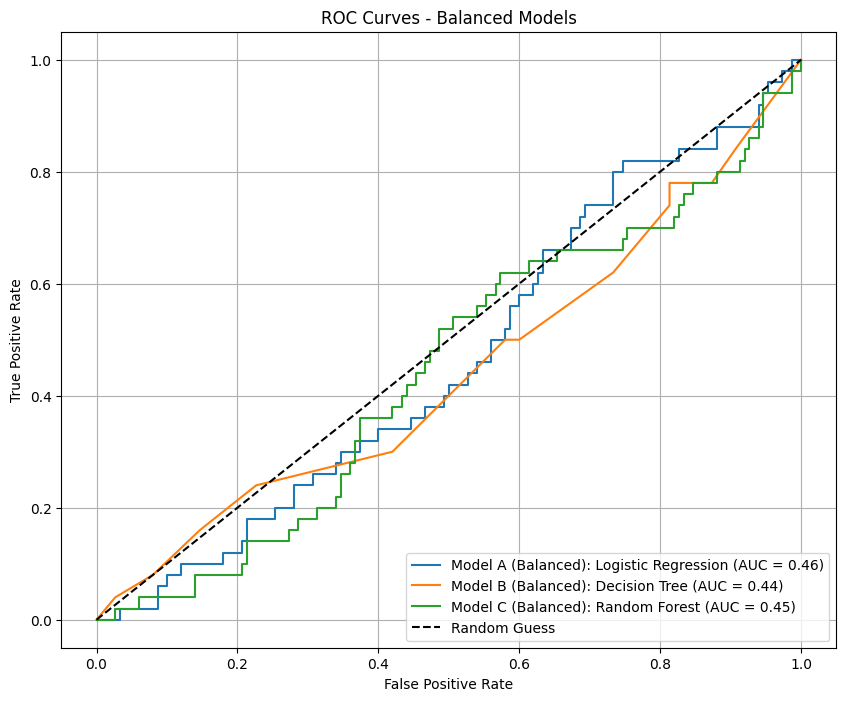

,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,ROC AUC
0,Model A (Balanced): Logistic Regression,47.50%,21.65%,42.00%,28.57%,0.4644
1,Model B (Balanced): Decision Tree,44.00%,22.32%,50.00%,30.86%,0.4427
2,Model C (Balanced): Random Forest,61.50%,11.43%,8.00%,9.41%,0.4473


In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Define new balanced models
balanced_models = {
    'Model A (Balanced): Logistic Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                                              ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
    'Model B (Balanced): Decision Tree': Pipeline(steps=[('preprocessor', preprocessor),
                                                         ('classifier', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))]),
    'Model C (Balanced): Random Forest': Pipeline(steps=[('preprocessor', preprocessor),
                                                         ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42))])
}

balanced_results = []
plt.figure(figsize=(10, 8))

for name, model in balanced_models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict class and probabilities
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    balanced_results.append({
        'Model': name,
        'Accuracy': f"{(acc * 100):.2f}%",
        'Precision': f"{(prec * 100):.2f}%",
        'Recall (Sensitivity)': f"{(rec * 100):.2f}%",
        'F1-Score': f"{(f1 * 100):.2f}%",
        'ROC AUC': f"{roc_auc:.4f}"
    })

    # Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Balanced Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

balanced_summary_df = pd.DataFrame(balanced_results)
display(balanced_summary_df)